# **Word2vec sobre un corpus de la RAE en español**

Este es un ejemplo del uso de Word2vec-Gensim  sobre un dataset de la RAE, el corpus es un archivo de texto crudo  que tiene 100.000 palabras y 11 megas el cual fue entrenado con     el método de skip-gram con representaciones vectoriales de 300.

In [ ]:
# reveal.js presentation configuration
from notebook.services.config import ConfigManager


cm = ConfigManager()
cm.update('livereveal', {
              'theme': 'league',
              'transition': 'fade',
              'center': 'false',
              'overview' : 'true',
              'start_slideshow_at': 'selected'
})

# import utility libraries
import numpy as np
from sklearn.decomposition import PCA
import pandas as pd
from matplotlib import pyplot as plt
plt.rcParams['figure.figsize'] = (15.0, 12.0)
#pd.core.format.set_option('notebook_repr_html',True)
pd.set_option('display.max_rows', 10)

# pretty print function
def pp(obj):
    print(pd.DataFrame(obj))

%matplotlib inline


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# Cargando el modelo con Gensim,  aquí se carga el archivo de vectores de dimensión 300.

In [ ]:
import gensim
from gensim.models import KeyedVectors
from gensim.test.utils import datapath
# import wrod2vec model from gensim
from gensim.models.word2vec import Word2Vec

# load Google News pre-trained network

model = KeyedVectors.load_word2vec_format("/content/drive/MyDrive/Colab-Notebooks/word2vec_skip-gram_model_300.txt", binary=False)

# Las palabras relacionadas semánticamente tienen representaciones similares

Este es el vector de la palabra computer de dimensión 300 [ 0.28652737  0.14513513  0.01814971 -0.23869419  0.10582032 -0.31924027
  0.29314741  0.32044747 -0.06216922 -0.17784142  0.11604799 -0.13249356
 -0.16918284  0.13090102 -0.23394613 -0.1734051  -0.05614499  0.14923489
  0.15652193 -0.13100308 -0.07760213 -0.11069286  0.08715811  0.09351144
  0.18451096 -0.29887408 -0.1916575   0.17915781 -0.03441298 -0.12827487
  0.03725257 -0.06524328  0.14153488  0.0326452   0.10578125  0.00409768
  0.1826333  -0.01705311  0.10523685 -0.27243298 -0.03470076  0.1248417
  0.05262247 -0.2766848  -0.07649112  0.16741699  0.00325122  0.15242052
 -0.08202402  0.18977568 -0.08241414 -0.22582142 -0.15275688  0.11814617
  0.05596272  0.3265759  -0.0050008   0.08132057 -0.04847357 -0.06373876
 -0.02335124 -0.09561907  0.07938397  0.12515868 -0.06879054  0.09023423
  0.03072036  0.11939111 -0.24930084  0.13079439  0.03432553  0.3681599
  0.11149225 -0.21097387  0.21713856 -0.11851957 -0.05314878 -0.1268

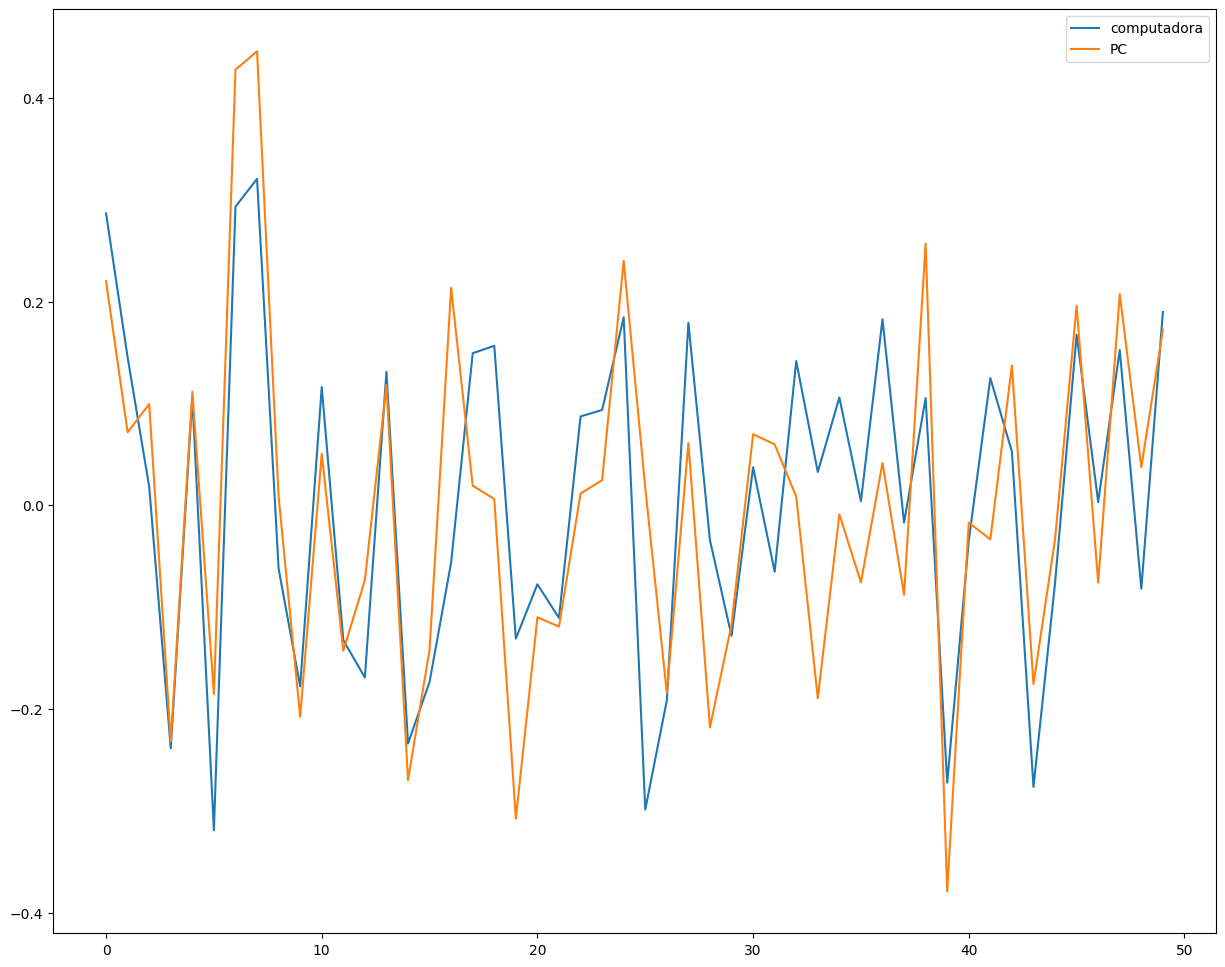

In [ ]:
from matplotlib import pyplot as plt
plt.plot(model['computadora'][:50], label = 'computadora')
plt.plot(model['PC'][:50], label = 'PC')
plt.legend()
print('Este es el vector de la palabra computer de dimensión 300',model['computadora'])
print(len(model['computadora']))

# La similaridad semántica = representación vectorial de la similaridad

In [ ]:
pp(model.most_similar(positive=['ciudad']))

           0         1
0      fecha  0.902076
1    capital  0.899384
2    entrega  0.896076
3      etapa  0.895343
4     región  0.895099
5      época  0.894691
6    reunión  0.894297
7       fase  0.893362
8     sesión  0.891247
9  provincia  0.890321


# Resolviendo analogías

* **man** es a  **woman** como  **king** es a  **??**
* Las relaciones son codificadas como diferencia de vectores de palabras:
$$ f(\textrm{"woman"}) - f(\textrm{"man"}) = f(\textrm{"??"}) - f(\textrm{"king"})$$
* Podemos al vector de **king** la relación del vector codificada: $$ f(\textrm{"king"}) + (f(\textrm{"woman"}) - f(\textrm{"man"})) = f(\textrm{"??"}) $$

In [ ]:
result = model.most_similar(negative=['hombre'],
                            positive=['mujer', 'rey'])
pp(result)


          0         1
0    fiesta  0.896308
1     flota  0.894257
2  preciosa  0.893698
3   sonrisa  0.891206
4     salsa  0.889665
5    señora  0.889271
6    receta  0.888465
7    AZUCAR  0.885865
8   hermana  0.885180
9  Catedral  0.884225


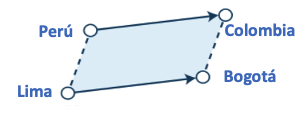

In [ ]:
result = model.most_similar(negative=['Perú'],
                            positive=['Colombia', 'Lima'])
pp(result)


           0         1
0    Araceli  0.916676
1     Bogotá  0.912101
2   Valencia  0.907155
3      París  0.903090
4    Granada  0.902368
5  Americano  0.898261
6      Tyson  0.896051
7  Barcelona  0.891210
8     Empleo  0.890154
9        7.2  0.890113


# Con la vectorización del curpus se pueden realizar consulatas de analogías

In [ ]:
def plot_data(orig_data, labels):
    pca = PCA(n_components=2)
    data = pca.fit_transform(orig_data)
    plt.figure(figsize=(7, 5), dpi=100)
    plt.plot(data[:,0], data[:,1], '.')
    for i in range(len(data)):
        plt.annotate(labels[i], xy = data[i])
    for i in range(len(data)/2):
        plt.annotate("",
                xy=data[i],
                xytext=data[i+len(data)/2],
                arrowprops=dict(arrowstyle="->",
                                connectionstyle="arc3")
                )

In [ ]:
def analogy(worda, wordb, wordc):
    result = model.most_similar(negative=[worda],
                                positive=[wordb, wordc])
    return result[0][0]
countries = ['Mexico', 'Colombia',  'Venezuela', 'France', 'Spain', 'China']
presidents = [analogy('Colombia', 'Duque', country) for country in countries]
pp(zip(countries,presidents))

           0              1
0     Mexico        Lampard
1   Colombia          Erick
2  Venezuela        Velasco
3     France  ZhannaYérkina
4      Spain             FB
5      China     CONSIGANSE


TypeError: ignored

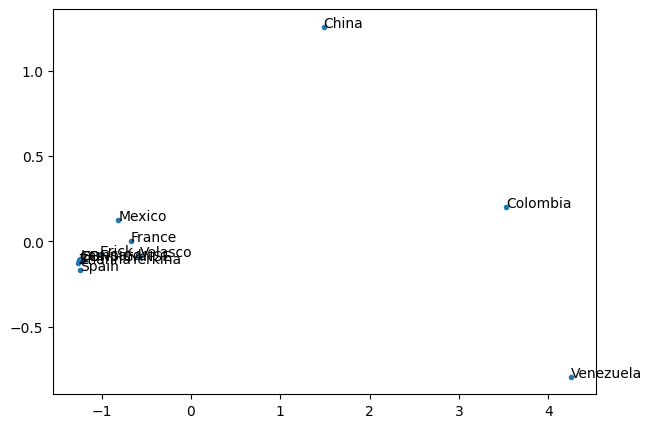

In [ ]:
labels = countries + presidents
data = [model[w] for w in labels]
plot_data(data, labels)

In [ ]:
pp(model.most_similar(positive=['México', 'river']))

            0         1
0   Argentina  0.924502
1     lanzada  0.920389
2       Chile  0.917509
3       China  0.916373
4          DF  0.914160
5       IAATO  0.912901
6   provincia  0.910426
7       Playa  0.909915
8       India  0.908217
9  Revolución  0.908015


## Visualizing embeddings with t-sne

Visualizaremos las 2000 palabras más frecuentes en inglés  (http://www.rupert.id.au/resources/4000-most-common-english-words-csv.csv).

In [ ]:

target_words = [line.strip().lower() for line in open("/content/drive/MyDrive/Colab-Notebooks/palabras.csv")][:300]
words = [word for word in target_words if word in model]
target_matrix = np.array([model[word] for word in words])

* t-Distributed Stochastic Neighbor Embedding (t-SNE) dimensionality reduction tecnique Well suited for the visualization of high-dimensional datasets (http://lvdmaaten.github.io/tsne/code/tsne_python.zip)

In [ ]:
#from sklearn.manifold import tsne
from tsne import tsne
reduced_matrix = tsne(target_matrix, 2);

Preprocessing the data using PCA...
Computing pairwise distances...
Computing P-values for point 0 of 298...
Mean value of sigma: 3.360700
Iteration 10: error is 14.354354
Iteration 20: error is 13.281523
Iteration 30: error is 13.927890
Iteration 40: error is 14.281796
Iteration 50: error is 14.005001
Iteration 60: error is 14.086873
Iteration 70: error is 13.926880
Iteration 80: error is 14.176172
Iteration 90: error is 14.145997
Iteration 100: error is 13.949194
Iteration 110: error is 1.689296
Iteration 120: error is 1.199442
Iteration 130: error is 1.043720
Iteration 140: error is 0.949810
Iteration 150: error is 0.869484
Iteration 160: error is 0.839339
Iteration 170: error is 0.809331
Iteration 180: error is 0.785193
Iteration 190: error is 0.773439
Iteration 200: error is 0.763121
Iteration 210: error is 0.759269
Iteration 220: error is 0.754603
Iteration 230: error is 0.749847
Iteration 240: error is 0.747060
Iteration 250: error is 0.744962
Iteration 260: error is 0.743412
It

In [ ]:
max_x = np.amax(reduced_matrix, axis=0)[0]
max_y = np.amax(reduced_matrix, axis=0)[1]

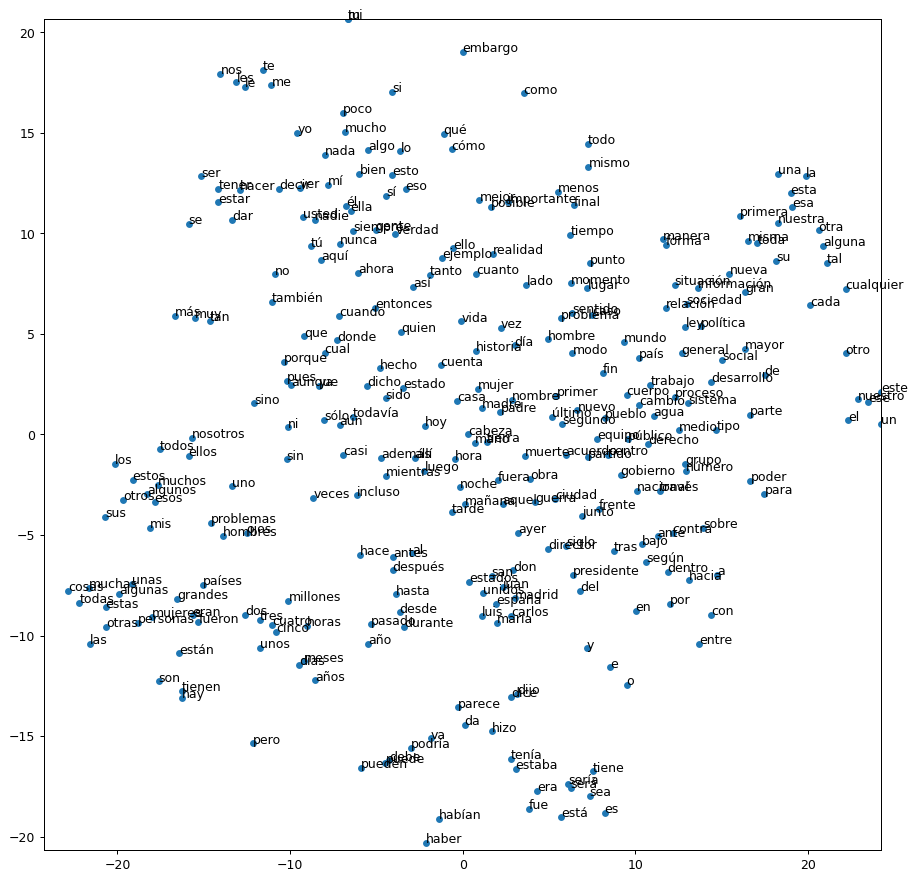

In [ ]:
plt.figure(figsize=(12, 12), dpi=90); plt.xlim((-max_x,max_x)); plt.ylim((-max_y,max_y))
plt.scatter(reduced_matrix[:, 0], reduced_matrix[:, 1], 20);
for idx, word in enumerate(words[:]):
    x = reduced_matrix[idx, 0]
    y = reduced_matrix[idx, 1]
    plt.annotate(word, (x,y))